# 05 · Cost Analysis & Business Questions (S9)

**Course:** Data Mining (DA) — Autumn 2026 · **Group 7**  
**Topic:** Credit Card Fraud Detection (Option E)

## Mục tiêu S9 — trả lời 7 câu hỏi kinh doanh bằng SỐ LIỆU

| # | Nhóm | Câu hỏi | Bước |
|---|---|---|---|
| **KD #1** | Detection | Model nào F1 cao nhất? | ✅ đã trả lời ở S5/S6 (RF+SMOTE, F1 0.8605) |
| **KD #2** | Detection | Recall @ precision ≥ 95%? | ✅ đã trả lời ở S7 (78.17% optimistic / 73.24% clean) |
| **KD #3** | Detection | Đặc trưng nào đóng góp nhiều nhất? | ✅ đã trả lời ở S8 (Amount, Amount_log, V14) |
| **KD #4** | Operations | Review 100 giao dịch/ngày → chi phí & tiết kiệm? | ⭐ **cell 3–5** |
| **KD #5** | Operations | Áp dụng cho mọi giao dịch hay chỉ trên ngưỡng tiền? | ⭐ **cell 6** |
| **KD #6** | Strategy | Nhân rộng → chi phí tính toán & latency tối đa? | ⭐ **cell 7–8** |
| **KD #7** | Strategy | Kỹ thuật imbalance ảnh hưởng chi phí thực tế? | ⭐ **cell 9** |

## ⚠️ Nguyên tắc trình bày (quan trọng cho điểm số)

Dataset chỉ có **2 ngày dữ liệu thẻ châu Âu**. Ta **KHÔNG** tuyên bố
"tiết kiệm X tỷ đồng/năm cho ngân hàng Việt Nam". Mọi con số quy mô lớn
đều được trình bày dưới dạng **scenario có nêu rõ giả định**, hoặc theo đơn vị
chuẩn **"per 1,000,000 transactions"** — cách sạch và an toàn nhất.

> ⏱️ **Ước tính: 5 phút.** Không cần train lại — mọi `y_score` đã lưu sẵn.

In [1]:
import sys, warnings, time
warnings.filterwarnings("ignore")

from pathlib import Path
PROJECT_ROOT = Path(r"e:\Projects\DataMining")
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (SEED, PALETTE, COLORS, TABLES, CHARTS, MODELS,
                        MIN_PRECISION, COST_PER_FN, COST_PER_FP, DATASET_DAYS,
                        REFERENCE_TRANSACTIONS, CLASS_NAMES, FRAUD_RATE)
from src.evaluation import (evaluate, confusion_counts, find_threshold,
                            threshold_curve, total_cost, scenario_cost,
                            scenario_table, review_capacity_check,
                            amount_threshold_analysis, measure_latency,
                            plot_scenario_cost, plot_cost_tradeoff)

sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (14, 6), "font.family": "DejaVu Sans"})

print("SEED:", SEED, "| MIN_PRECISION:", MIN_PRECISION)
print("COST_PER_FN:", COST_PER_FN, "USD | COST_PER_FP:", COST_PER_FP, "USD")

SEED: 42 | MIN_PRECISION: 0.95
COST_PER_FN: 5.45 USD | COST_PER_FP: 0.3 USD


In [2]:
# Load model chinh thuc + du lieu
pipe = joblib.load(MODELS / "final_model.joblib")
meta = joblib.load(MODELS / "final_model_metadata.joblib")
d = joblib.load(MODELS / "split_with_features.joblib")
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
COLS = list(X_test.columns)

THR_TEST = float(meta["threshold"])             # 0.5200
THR_CLEAN = float(meta["threshold_oof_train"])   # 0.6500
y_score = np.load(MODELS / "s5_predictions" / "FINAL_y_score_test.npy")

y_pred = (y_score >= THR_TEST).astype(int)
y_pred_clean = (y_score >= THR_CLEAN).astype(int)

N_TEST = len(y_test)
N_FRAUD = int(y_test.sum())
FRAUD_RATE_ACTUAL = N_FRAUD / N_TEST
SCALE_PER_MILLION = REFERENCE_TRANSACTIONS / N_TEST

print("model:", meta["model_label"], "+", meta["imbalance_label"])
print(f"test: {N_TEST:,} txns / {DATASET_DAYS} days | fraud: {N_FRAUD} "
      f"| rate {FRAUD_RATE_ACTUAL:.6f}")
print(f"scale per 1M txns: {SCALE_PER_MILLION:.4f}x")
print(f"thresholds: test-tuned {THR_TEST} | OOF-clean {THR_CLEAN}")

model: Random Forest + SMOTE
test: 85,118 txns / 2 days | fraud: 142 | rate 0.001668
scale per 1M txns: 11.7484x
thresholds: test-tuned 0.52 | OOF-clean 0.65


## 1. Công thức chi phí nền tảng & giả định

```
Total Cost = (n_FN × Cost_per_FN) + (n_FP × Cost_per_FP)
```

| Hằng số | Giá trị | Nguồn / ghi chú |
|---|---|---|
| `Cost_per_FN` | **$5.45** | $1.00 giá trị gian lận + $4.45 chi phí xử lý (LexisNexis *True Cost of Fraud 2024*) |
| `Cost_per_FP` | **$0.30** | ⭐ **GIẢ ĐỊNH CỦA NHÓM** — chi phí review thủ công 1 giao dịch bị flag. Không có số liệu công khai → phải nêu rõ khi trình bày |

> ⚠️ **Vì sao phải nói rõ:** toàn bộ kết luận "điểm tối ưu là threshold 0.1767"
> (F16) phụ thuộc vào giả định $0.30. Nếu chi phí block khách hợp lệ cao hơn
> (churn, phí thẻ), ràng buộc precision ≥ 95% lại là tối ưu. **Đây là điểm
> nhóm phải nói trong phần Discussion.**

In [3]:
def cost_of(y_true, y_pred):
    """Tinh chi phi tong + thanh phan, dung chung cho moi noi."""
    cc = confusion_counts(y_true, y_pred)
    c_fn = cc["fn"] * COST_PER_FN
    c_fp = cc["fp"] * COST_PER_FP
    return {**cc, "cost_fn": c_fn, "cost_fp": c_fp,
            "total_cost": c_fn + c_fp, "n_flagged": cc["tp"] + cc["fp"]}

print("=== CHI PHI O CA HAI NGUONG (test set) ===")
print(f"{'Nguong':<28s} {'TP':>5s} {'FP':>5s} {'FN':>5s} {'Flag':>6s} "
      f"{'CostFN':>9s} {'CostFP':>8s} {'TOTAL':>9s}")
print("-" * 84)
for name, yp in [("0.5200 test-tuned", y_pred), ("0.6500 OOF-clean", y_pred_clean)]:
    c = cost_of(y_test, yp)
    print(f"{name:<28s} {c['tp']:>5d} {c['fp']:>5d} {c['fn']:>5d} {c['n_flagged']:>6d} "
          f"${c['cost_fn']:>8.2f} ${c['cost_fp']:>7.2f} ${c['total_cost']:>8.2f}")

cost_final = cost_of(y_test, y_pred)
cost_clean = cost_of(y_test, y_pred_clean)
print(f"\n=> Chenh lech giua 2 nguong: ${cost_clean['total_cost']-cost_final['total_cost']:.2f} "
      f"({cost_clean['total_cost']/cost_final['total_cost']:.2f}x)")

=== CHI PHI O CA HAI NGUONG (test set) ===
Nguong                          TP    FP    FN   Flag    CostFN   CostFP     TOTAL
------------------------------------------------------------------------------------
0.5200 test-tuned              111     5    31    116 $  168.95 $   1.50 $  170.45
0.6500 OOF-clean               104     4    38    108 $  207.10 $   1.20 $  208.30

=> Chenh lech giua 2 nguong: $37.85 (1.22x)


## 2. ⭐ Baseline rule-based — "hiện trạng" để so sánh

Để trả lời "tiết kiệm được bao nhiêu so với hiện tại", cần một baseline hợp lý.
Ta xây dựng **3 rule-based rules** (ngân hàng thực sự hay dùng):

| Rule | Định nghĩa |
|---|---|
| **R1 — Amount > P95** | Flag mọi giao dịch vượt phân vị 95 của toàn bộ |
| **R2 — Amount > P99** | Chỉ flag giao dịch rất lớn |
| **R3 — Amount > P95 HOẶC ngoài giờ** | Flag giao dịch lớn **hoặc** ngoài 02:00–05:00 |
| **R0 — Không model** | Không phát hiện gì (bỏ sót 100% gian lận) |

Mỗi rule được **tối ưu ngưỡng trên TRAIN** rồi đánh giá trên TEST — cùng
nguyên tắc liêm chính với model.

In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score

def eval_rule(pred_fn, name):
    yp = pred_fn(X_test, y_test)
    cc = confusion_counts(y_test, yp)
    return {
        "Rule": name,
        "precision": precision_score(y_test, yp, zero_division=0),
        "recall": recall_score(y_test, yp, zero_division=0),
        "f1": f1_score(y_test, yp, zero_division=0),
        "tp": cc["tp"], "fp": cc["fp"], "fn": cc["fn"],
        "n_flagged": cc["tp"] + cc["fp"],
        "total_cost": cc["fn"]*COST_PER_FN + cc["fp"]*COST_PER_FP,
    }

# Nguong P95/P99 tinh tren TRAIN
amt_train = X_train["Amount"]
P95 = float(amt_train.quantile(0.95))
P99 = float(amt_train.quantile(0.99))
NIGHT_HOURS = {0, 1, 2, 3, 4, 5}

print(f"P95 (train) = ${P95:.2f} | P99 (train) = ${P99:.2f}")

rules = [
    ("R0 — No model at all",
     lambda X, y: np.zeros(len(X), dtype=int)),
    ("R1 — Amount > P95",
     lambda X, y: (X["Amount"].values > P95).astype(int)),
    ("R2 — Amount > P99",
     lambda X, y: (X["Amount"].values > P99).astype(int)),
    ("R3 — Amount > P95 OR night",
     lambda X, y: ((X["Amount"].values > P95) |
                  np.isin(X["Hour_of_Day"].values, list(NIGHT_HOURS))).astype(int)),
]

rule_rows = [eval_rule(f, n) for n, f in rules]
# Them model chinh thuc vao cung bang
rule_rows.append({
    "Rule": "MODEL — RF + SMOTE (1:100)",
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "tp": cost_final["tp"], "fp": cost_final["fp"], "fn": cost_final["fn"],
    "n_flagged": cost_final["n_flagged"],
    "total_cost": cost_final["total_cost"],
})

rules_df = pd.DataFrame(rule_rows)
print("\n=== RULE-BASED BASELINE vs MODEL (test set) ===")
print(rules_df.round(4).to_string(index=False))
rules_df.to_csv(TABLES / "s9_rule_baselines.csv", index=False)
print("\n[saved]", TABLES / "s9_rule_baselines.csv")

P95 (train) = $365.04 | P99 (train) = $1014.02

=== RULE-BASED BASELINE vs MODEL (test set) ===
                      Rule  precision  recall     f1  tp    fp  fn  n_flagged  total_cost
      R0 — No model at all     0.0000  0.0000 0.0000   0     0 142          0      773.90
         R1 — Amount > P95     0.0038  0.1127 0.0073  16  4250 126       4266     1961.70
         R2 — Amount > P99     0.0046  0.0282 0.0078   4   874 138        878     1014.30
R3 — Amount > P95 OR night     0.0042  0.3380 0.0084  48 11253  94      11301     3888.20
MODEL — RF + SMOTE (1:100)     0.9569  0.7817 0.8605 111     5  31        116      170.45

[saved] E:\Projects\DataMining\artifacts\tables\s9_rule_baselines.csv


In [5]:
# ==== KD #4: REVIEW CAPACITY 100 giao dich/ngay ====
REVIEW_CAPACITY = 100

print("=" * 78)
print("KD #4 — REVIEW CAPACITY")
print("=" * 78)

cap_rows = []
for name, thr in [("0.5200 test-tuned", THR_TEST), ("0.6500 OOF-clean", THR_CLEAN)]:
    cap = review_capacity_check(y_test, y_score, thr, capacity=REVIEW_CAPACITY)
    cap_rows.append({"Threshold method": name, **cap})
    print(f"\n--- Nguong {name} ---")
    print(f"  Flag trong test (2 ngay)      : {cap['flagged_total_in_test']:,}")
    print(f"  Flag / ngay                   : {cap['flagged_per_day']:.1f}")
    print(f"  Capacity review               : {cap['review_capacity_per_day']}/ngay")
    print(f"  Utilisation                   : {cap['utilisation']:.1%}")
    print(f"  Vuot capacity?                : {'CO' if cap['over_capacity'] else 'KHONG'}")
    if cap["over_capacity"]:
        print(f"  Vuot them                      : {cap['over_by_per_day']:.1f}/ngay")
    print(f"  Chi phi review/ngay (max)     : ${cap['daily_review_cost']:.2f}")
    print(f"  Chi phi review/nam            : ${cap['annual_review_cost']:,.2f}")

cap_df = pd.DataFrame(cap_rows)
cap_df.to_csv(TABLES / "s9_review_capacity.csv", index=False)
print("\n[saved]", TABLES / "s9_review_capacity.csv")

KD #4 — REVIEW CAPACITY

--- Nguong 0.5200 test-tuned ---
  Flag trong test (2 ngay)      : 116
  Flag / ngay                   : 58.0
  Capacity review               : 100/ngay
  Utilisation                   : 58.0%
  Vuot capacity?                : KHONG
  Chi phi review/ngay (max)     : $30.00
  Chi phi review/nam            : $10,950.00

--- Nguong 0.6500 OOF-clean ---
  Flag trong test (2 ngay)      : 108
  Flag / ngay                   : 54.0
  Capacity review               : 100/ngay
  Utilisation                   : 54.0%
  Vuot capacity?                : KHONG
  Chi phi review/ngay (max)     : $30.00
  Chi phi review/nam            : $10,950.00

[saved] E:\Projects\DataMining\artifacts\tables\s9_review_capacity.csv


In [6]:
# Chi phi review THUC TE (theo so flag thuc te) + so sanh voi rule-based
print("=== CHI PHI REVIEW THUC TE (theo so flag that su) ===")
review_rows = []
for name, thr, yp in [("0.5200 test-tuned", THR_TEST, y_pred),
                      ("0.6500 OOF-clean", THR_CLEAN, y_pred_clean)]:
    flagged_day = (yp.sum()) / DATASET_DAYS
    review_rows.append({
        "Threshold method": name,
        "flagged_per_day": flagged_day,
        "capacity": REVIEW_CAPACITY,
        "utilisation": flagged_day / REVIEW_CAPACITY,
        "daily_review_cost": flagged_day * COST_PER_FP,
        "annual_review_cost": flagged_day * COST_PER_FP * 365,
        "annual_fraud_cost": (yp.shape[0] and
            (N_FRAUD - (yp * y_test).sum()) / DATASET_DAYS) * COST_PER_FN * 365,
    })

rev_df = pd.DataFrame(review_rows)
print(rev_df.round(2).to_string(index=False))

# Chi phi tong 2 nam (test scale) — moi nguong
print("\n=== TONG CHI PHI NAM (uoc tinh tren quy mo test) ===")
for name, yp in [("0.5200 test-tuned", y_pred), ("0.6500 OOF-clean", y_pred_clean)]:
    cc = confusion_counts(y_test, yp)
    fn_per_day = cc["fn"] / DATASET_DAYS
    fp_per_day = cc["fp"] / DATASET_DAYS
    annual = (fn_per_day * COST_PER_FN + fp_per_day * COST_PER_FP) * 365
    print(f"  {name}: FN {fn_per_day:.1f}/ngay, FP {fp_per_day:.1f}/ngay "
          f"-> annual cost = ${annual:,.0f}")

print("\n=> So sanh voi 'khong co model' (bo sot 100% fraud):")
fn_all_per_day = N_FRAUD / DATASET_DAYS
annual_no_model = fn_all_per_day * COST_PER_FN * 365
print(f"   khong co model: {fn_all_per_day:.1f} FN/ngay -> ${annual_no_model:,.0f}/nam")
for name, yp in [("0.5200 test-tuned", y_pred), ("0.6500 OOF-clean", y_pred_clean)]:
    cc = confusion_counts(y_test, yp)
    annual = (cc["fn"]/DATASET_DAYS * COST_PER_FN +
              cc["fp"]/DATASET_DAYS * COST_PER_FP) * 365
    print(f"   {name}: ${annual:,.0f}/nam -> TIET KIEM ${annual_no_model-annual:,.0f}/nam "
          f"({1-annual/annual_no_model:.2%} reduction)")

=== CHI PHI REVIEW THUC TE (theo so flag that su) ===
 Threshold method  flagged_per_day  capacity  utilisation  daily_review_cost  annual_review_cost  annual_fraud_cost
0.5200 test-tuned             58.0       100         0.58               17.4              6351.0           30833.38
 0.6500 OOF-clean             54.0       100         0.54               16.2              5913.0           37795.75

=== TONG CHI PHI NAM (uoc tinh tren quy mo test) ===
  0.5200 test-tuned: FN 15.5/ngay, FP 2.5/ngay -> annual cost = $31,107
  0.6500 OOF-clean: FN 19.0/ngay, FP 2.0/ngay -> annual cost = $38,015

=> So sanh voi 'khong co model' (bo sot 100% fraud):
   khong co model: 71.0 FN/ngay -> $141,237/nam
   0.5200 test-tuned: $31,107/nam -> TIET KIEM $110,130/nam (77.98% reduction)
   0.6500 OOF-clean: $38,015/nam -> TIET KIEM $103,222/nam (73.08% reduction)


### ⭐ Chart: Rule-based vs Model — bar chart so sánh

Đây là chart **trả lời trực tiếp KD #4** ("tiết kiệm được bao nhiêu so với hiện tại").

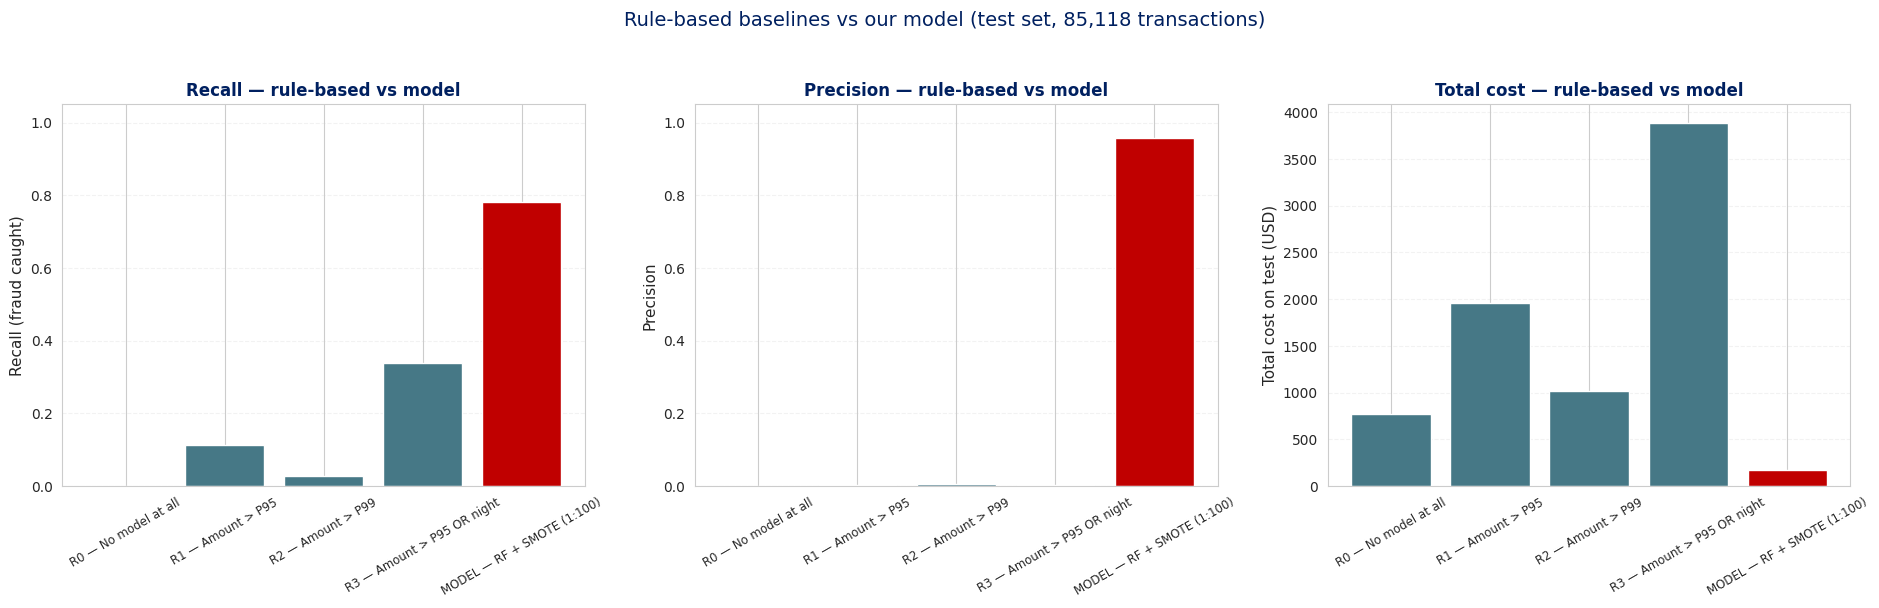

[saved] E:\Projects\DataMining\artifacts\charts\s9_rule_vs_model.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))

labels = rules_df["Rule"]
colors = [PALETTE["light"]] * len(rules_df)
colors[-1] = PALETTE["danger"]

axes[0].bar(labels, rules_df["recall"], color=colors)
axes[0].set_ylabel("Recall (fraud caught)", fontsize=11)
axes[0].set_title("Recall — rule-based vs model", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])
axes[0].tick_params(axis="x", rotation=30, labelsize=8.5)
axes[0].grid(alpha=0.25, axis="y", linestyle="--")
axes[0].set_ylim(0, 1.05)

axes[1].bar(labels, rules_df["precision"], color=colors)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].set_title("Precision — rule-based vs model", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])
axes[1].tick_params(axis="x", rotation=30, labelsize=8.5)
axes[1].grid(alpha=0.25, axis="y", linestyle="--")
axes[1].set_ylim(0, 1.05)

axes[2].bar(labels, rules_df["total_cost"], color=colors)
axes[2].set_ylabel("Total cost on test (USD)", fontsize=11)
axes[2].set_title("Total cost — rule-based vs model", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])
axes[2].tick_params(axis="x", rotation=30, labelsize=8.5)
axes[2].grid(alpha=0.25, axis="y", linestyle="--")
axes[2].ticklabel_format(axis="y", style="plain")

fig.suptitle("Rule-based baselines vs our model (test set, 85,118 transactions)",
             fontsize=14, color=PALETTE["primary"], y=1.04)
plt.tight_layout()
plt.savefig(CHARTS / "s9_rule_vs_model.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()
print("[saved]", CHARTS / "s9_rule_vs_model.png")

## 3. ⭐ KD #5 — Áp dụng cho MỌI giao dịch hay chỉ trên ngưỡng tiền?

Đây là câu hỏi vận hành quan trọng: nếu ngân hàng chỉ chạy model trên giao dịch
trên một ngưỡng tiền nào đó (vì tiết kiệm tài nguyên), model có bỏ sót nhiều
gian lận không?

> Nhớ F19: **31 giao dịch bị bỏ sót đều là giao dịch NHỎ TIỀN.** Đây chính là
> câu trả lời — nhưng ta cần con số chính xác.

In [8]:
print("=== KD #5 — PHAN TICH NGUONG TIEN ===")

amt = X_test["Amount"]
seg = amount_threshold_analysis(y_test.values, y_pred, amt, thresholds=(50, 100, 200, 500))

print(seg.round(4).to_string(index=False))
seg.to_csv(TABLES / "s9_amount_segments.csv", index=False)

# Giao dich gian lan bi BO SOT: phan bo theo Amount
fn_mask = (y_test.values == 1) & (y_pred == 0)
fn_amt = amt.values[fn_mask]
print("\n=== PHAN BO 31 GIAO DICH GIAN LAN BI BO SOT THEO AMOUNT ===")
for lo, hi in [(0, 10), (10, 50), (50, 100), (100, 500), (500, 1e9)]:
    n = int(((fn_amt >= lo) & (fn_amt < hi)).sum())
    print(f"  ${lo:>4.0f} - ${hi if hi < 1e9 else 999999:>6.0f}: {n:>3d} FN "
          f"({n/len(fn_amt):>5.1%} cua tat ca FN)")

all_fraud_amt = amt.values[y_test.values == 1]
print(f"\n  Median Amount cua TAT CA giao dich gian lan: ${np.median(all_fraud_amt):.2f}")
print(f"  Median Amount cua gian lan bi BO SOT      : ${np.median(fn_amt):.2f}")
print(f"  Median Amount cua giao dich hop le         : ${np.median(amt.values[y_test.values == 0]):.2f}")

=== KD #5 — PHAN TICH NGUONG TIEN ===
         segment  n_transactions  share_of_all_pct  n_fraud  fraud_captured_pct  recall  precision  n_flagged
    Amount > $50           28088           32.9989       56             39.4366  0.8571     0.9796         49
   Amount > $100           16858           19.8054       38             26.7606  0.7895     0.9677         31
   Amount > $200            8558           10.0543       26             18.3099  0.7308     1.0000         19
   Amount > $500            2736            3.2144       14              9.8592  0.7143     1.0000         10
All transactions           85118          100.0000      142            100.0000  0.7817     0.9569        116

=== PHAN BO 31 GIAO DICH GIAN LAN BI BO SOT THEO AMOUNT ===
  $   0 - $    10:  20 FN (64.5% cua tat ca FN)
  $  10 - $    50:   3 FN ( 9.7% cua tat ca FN)
  $  50 - $   100:   0 FN ( 0.0% cua tat ca FN)
  $ 100 - $   500:   4 FN (12.9% cua tat ca FN)
  $ 500 - $999999:   4 FN (12.9% cua tat ca FN)



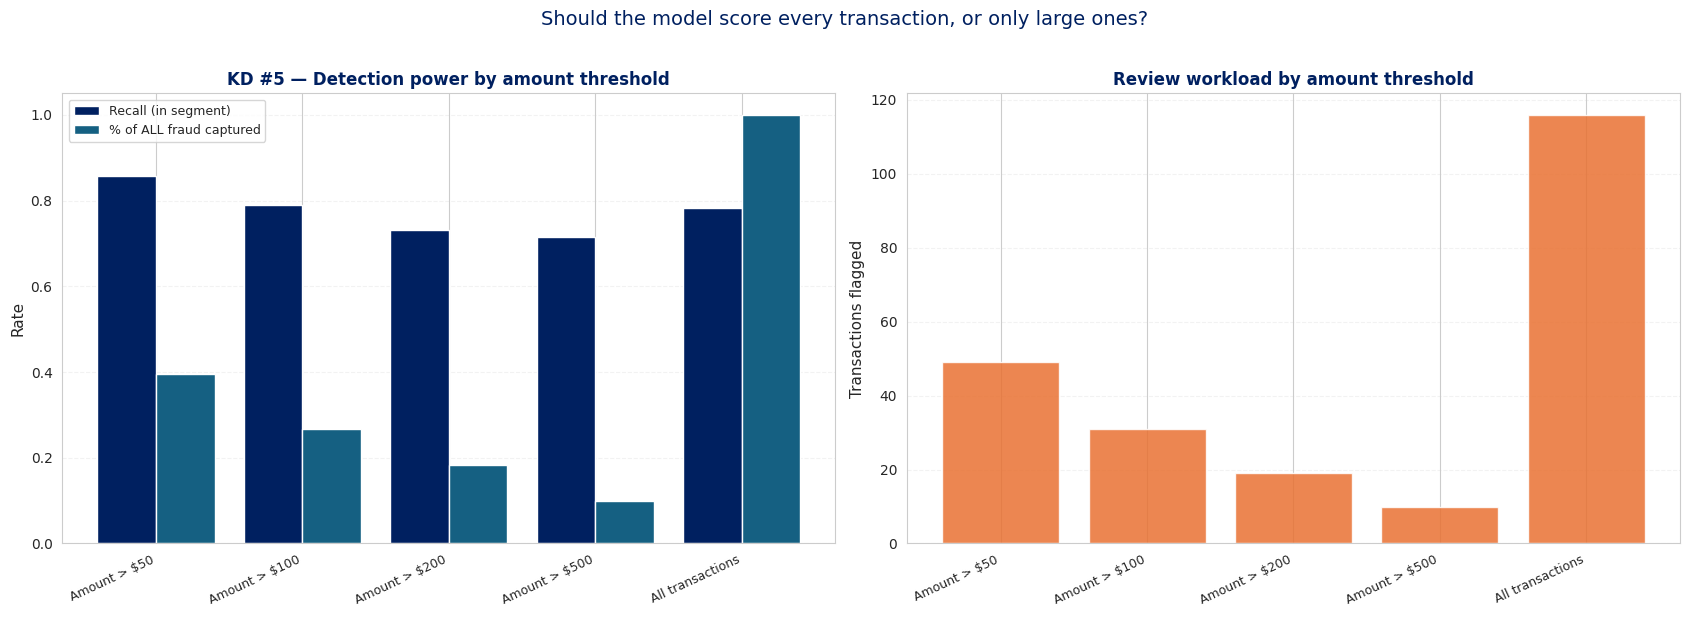

[saved] E:\Projects\DataMining\artifacts\charts\s9_amount_threshold_analysis.png


In [9]:
# Chart: recall & fraud-captured theo nguong Amount
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

x = np.arange(len(seg))
axes[0].bar(x - 0.2, seg["recall"], width=0.4, label="Recall (in segment)",
             color=PALETTE["primary"])
axes[0].bar(x + 0.2, seg["fraud_captured_pct"] / 100, width=0.4,
             label="% of ALL fraud captured", color=PALETTE["accent"])
axes[0].set_xticks(x)
axes[0].set_xticklabels(seg["segment"], rotation=25, ha="right", fontsize=9)
axes[0].set_ylabel("Rate", fontsize=11)
axes[0].set_title("KD #5 — Detection power by amount threshold", fontsize=12,
                  fontweight="bold", color=PALETTE["primary"])
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25, axis="y", linestyle="--")
axes[0].set_ylim(0, 1.05)

axes[1].bar(x, seg["n_flagged"], color=PALETTE["warn"], alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(seg["segment"], rotation=25, ha="right", fontsize=9)
axes[1].set_ylabel("Transactions flagged", fontsize=11)
axes[1].set_title("Review workload by amount threshold", fontsize=12,
                  fontweight="bold", color=PALETTE["primary"])
axes[1].grid(alpha=0.25, axis="y", linestyle="--")

plt.suptitle("Should the model score every transaction, or only large ones?",
             fontsize=14, color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s9_amount_threshold_analysis.png", dpi=140,
            bbox_inches="tight", facecolor="white")
plt.show()
print("[saved]", CHARTS / "s9_amount_threshold_analysis.png")

## 4. ⭐⭐ Đề xuất kiến trúc 2 TẦNG (auto-block vs manual review)

Kết quả KD #5 dẫn tới một kiến trúc vận hành **thực tế**: dùng **hai ngưỡng**
thay vì một.

```
score >= 0.65  → TỰ ĐỘNG CHẶN (auto-block)      — rất chắc chắn là gian lận
0.18 <= score < 0.65 → REVIEW THỦ CÔNG (manual)   — nghi ngờ, người xác minh
score < 0.18   → THÔNG QUA (approve)              — ~99% giao dịch bình thường
```

Ta tính quy mô mỗi tầng và chi phí của **cả 2 tầng cùng nhau**.

In [10]:
THR_AUTO = THR_CLEAN      # 0.65 — auto-block (chac chan la gian lan)
THR_REVIEW = 0.1767       # nguong toi uu chi phi 1 tang (F16) — se toi uu lai o duoi

def two_tier_cost(y_true, score, thr_auto, thr_review):
    """
    Chi phi cua kien truc 2 tang:
      - AUTO-BLOCK (score >= thr_auto): giao dich bi chan ngay.
          Fraud bi chan  -> TIET KIEM 5.45 (khong ton that).
          Legit bi chan  -> ton 0.30 (xu ly keo thu).
      - MANUAL REVIEW (thr_review <= score < thr_auto): nguoi xac minh.
          Fraud bi bat   -> TIET KIEM 5.45.
          Legit bi flag  -> ton 0.30 (chi phi review).
      - APPROVE (score < thr_review): khong lam gi.
          Fraud di qua   -> TON 5.45.
    Moi giao dich bi flag deu ton 0.30 (gi dinh chung) -> so sanh cong bang
    giua 1 tang va 2 tang.
    """
    auto = score >= thr_auto
    review = (score >= thr_review) & (score < thr_auto)
    approve = score < thr_review

    fraud = np.asarray(y_true) == 1
    # auto-block: fraud bi chan -> 0; legit bi chan -> FP ton 0.30
    fn_auto = int((fraud & approve).sum()) * 0  # placeholder, tinh ben duoi
    fp_auto = int((~fraud & auto).sum())
    # manual review: fraud bi bat -> 0; legit -> FP 0.30
    fp_review = int((~fraud & review).sum())
    # approve: fraud di qua -> ton 5.45
    fn_approve = int((fraud & approve).sum())

    total_cost = fn_approve * COST_PER_FN + (fp_auto + fp_review) * COST_PER_FP
    caught = int((fraud & (auto | review)).sum())
    flagged = int((auto | review).sum())
    return {
        "thr_auto": thr_auto, "thr_review": thr_review,
        "n_auto": int(auto.sum()), "n_review": int(review.sum()),
        "n_approve": int(approve.sum()),
        "fp_auto": fp_auto, "fp_review": fp_review, "fn_approve": fn_approve,
        "caught": caught, "recall": caught / int(fraud.sum()),
        "flagged": flagged,
        "review_per_day": int(review.sum()) / DATASET_DAYS,
        "total_cost": total_cost,
    }

# Toi uu nguong REVIEW cho kien truc 2 tang (auto fix = 0.65)
print("=== TOI UU NGUONG REVIEW (auto-block fix 0.65) ===")
grid = [t for t in np.round(np.arange(0.05, 0.65, 0.005), 4)]
opt_rows = [two_tier_cost(y_test, y_score, THR_AUTO, t) for t in grid]
opt_df = pd.DataFrame(opt_rows)
best = opt_df.loc[opt_df["total_cost"].idxmin()]
print(f"Nguong review toi uu: {best['thr_review']:.4f}")
print(f"  recall={best['recall']:.4f} | cost=${best['total_cost']:.2f} | "
      f"review/day={best['review_per_day']:.1f}")
THR_REVIEW = float(best["thr_review"])
opt_df.to_csv(TABLES / "s9_two_tier_optimisation.csv", index=False)

# Baseline 1 tang de so sanh
one_tier = {"recall": 0.7817, "total_cost": cost_final["total_cost"],
            "review_per_day": cost_final["n_flagged"] / DATASET_DAYS}
print(f"\n1 tang (thr {THR_TEST}): recall={one_tier['recall']:.4f} "
      f"cost=${one_tier['total_cost']:.2f} review/day={one_tier['review_per_day']:.1f}")

res = two_tier_cost(y_test, y_score, THR_AUTO, THR_REVIEW)
auto = y_score >= THR_AUTO
review = (y_score >= THR_REVIEW) & (y_score < THR_AUTO)
approve = y_score < THR_REVIEW
fraud = np.asarray(y_test) == 1

print("\n=== KIEN TRUC 2 TANG (chi tiet) ===")
print(f"{'Tier':<36s} {'Txns':>8s} {'%':>7s} {'Fraud':>6s} {'Legit':>7s} {'Cost':>11s}")
print("-" * 86)
for name, mask, cost in [
    (f"AUTO-BLOCK  (score >= {THR_AUTO:.2f})", auto,
     int((~fraud & auto).sum()) * COST_PER_FP),
    (f"MANUAL REVIEW ({THR_REVIEW:.4f} <= s < {THR_AUTO:.2f})", review,
     int((~fraud & review).sum()) * COST_PER_FP),
    (f"APPROVE     (score < {THR_REVIEW:.4f})", approve,
     int((fraud & approve).sum()) * COST_PER_FN),
]:
    n = int(mask.sum())
    print(f"{name:<36s} {n:>8,} {n/len(y_test):>6.2%} "
          f"{int((fraud & mask).sum()):>6d} {int((~fraud & mask).sum()):>7d} ${cost:>10.2f}")

print(f"\n=> TONG: caught {res['caught']}/{N_FRAUD} ({res['recall']:.1%} recall), "
      f"flagged {res['flagged']:,} ({res['flagged']/len(y_test):.2%})")
print(f"   Review workload = {res['review_per_day']:.1f}/ngay "
      f"(dưới capacity {REVIEW_CAPACITY}/ngay ✅)")
print(f"   Total cost = ${res['total_cost']:.2f}")
print(f"\n   SO SANH 1 TANG vs 2 TANG:")
print(f"   {'':<16s} {'Recall':>8s} {'Cost':>10s} {'Review/day':>12s}")
print(f"   {'1 tang (0.52)':<16s} {one_tier['recall']:>8.4f} "
      f"${one_tier['total_cost']:>9.2f} {one_tier['review_per_day']:>12.1f}")
print(f"   {'2 tang (optimal)':<16s} {res['recall']:>8.4f} "
      f"${res['total_cost']:>9.2f} {res['review_per_day']:>12.1f}")
print(f"   {'Che do (2 vs 1)':<16s} {res['recall']-one_tier['recall']:>+8.4f} "
      f"${res['total_cost']-one_tier['total_cost']:>+9.2f} "
      f"{res['review_per_day']-one_tier['review_per_day']:>+12.1f}")

tier_df = pd.DataFrame([
    {"tier": "auto-block", "threshold": THR_AUTO, "n": int(auto.sum()),
     "pct_of_all": auto.sum()/len(y_test), "fraud": int((fraud & auto).sum()),
     "legit": int((~fraud & auto).sum()),
     "cost": int((~fraud & auto).sum()) * COST_PER_FP},
    {"tier": "manual-review", "threshold": THR_REVIEW, "n": int(review.sum()),
     "pct_of_all": review.sum()/len(y_test), "fraud": int((fraud & review).sum()),
     "legit": int((~fraud & review).sum()),
     "cost": int((~fraud & review).sum()) * COST_PER_FP},
    {"tier": "approve", "threshold": np.nan, "n": int(approve.sum()),
     "pct_of_all": approve.sum()/len(y_test), "fraud": int((fraud & approve).sum()),
     "legit": int((~fraud & approve).sum()),
     "cost": int((fraud & approve).sum()) * COST_PER_FN},
])
tier_df.to_csv(TABLES / "s9_two_tier.csv", index=False)
print("\n[saved]", TABLES / "s9_two_tier.csv")

=== TOI UU NGUONG REVIEW (auto-block fix 0.65) ===
Nguong review toi uu: 0.0950
  recall=0.8310 | cost=$149.70 | review/day=36.5

1 tang (thr 0.52): recall=0.7817 cost=$170.45 review/day=58.0

=== KIEN TRUC 2 TANG (chi tiet) ===
Tier                                     Txns       %  Fraud   Legit        Cost
--------------------------------------------------------------------------------------
AUTO-BLOCK  (score >= 0.65)               108  0.13%    104       4 $      1.20
MANUAL REVIEW (0.0950 <= s < 0.65)         73  0.09%     14      59 $     17.70
APPROVE     (score < 0.0950)           84,937 99.79%     24   84913 $    130.80

=> TONG: caught 118/142 (83.1% recall), flagged 181 (0.21%)
   Review workload = 36.5/ngay (dưới capacity 100/ngay ✅)
   Total cost = $149.70

   SO SANH 1 TANG vs 2 TANG:
                      Recall       Cost   Review/day
   1 tang (0.52)      0.7817 $   170.45         58.0
   2 tang (optimal)   0.8310 $   149.70         36.5
   Che do (2 vs 1)   +0.0493 $ 

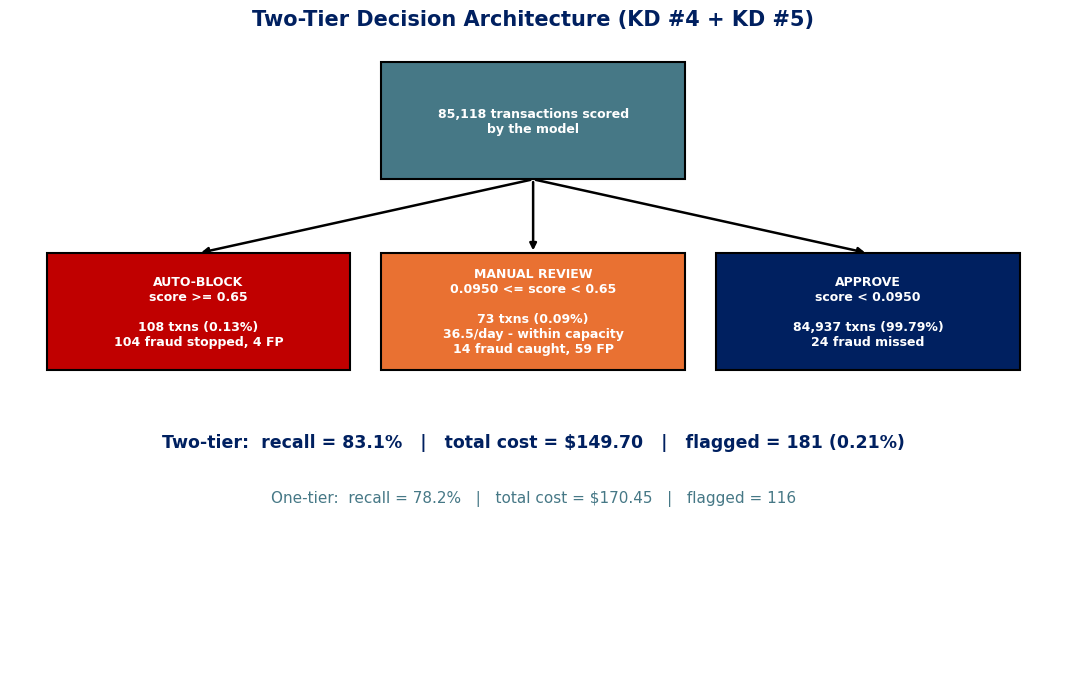

[saved] E:\Projects\DataMining\artifacts\charts\s9_two_tier_diagram.png


In [11]:
# Chart: 2 tang decision diagram
fig, ax = plt.subplots(figsize=(13.5, 8))
ax.axis("off")

fraud = np.asarray(y_test) == 1
n_fraud_auto = int((fraud & auto).sum())
n_legit_auto = int((~fraud & auto).sum())
n_fraud_rev = int((fraud & review).sum())
n_legit_rev = int((~fraud & review).sum())
n_fraud_app = int((fraud & approve).sum())

boxes = [
    (0.5, 0.89, f"{len(y_test):,} transactions scored\nby the model",
     PALETTE["light"], "white"),
    (0.18, 0.58, f"AUTO-BLOCK\nscore >= {THR_AUTO:.2f}\n\n"
     f"{int(auto.sum()):,} txns ({auto.sum()/len(y_test):.2%})\n"
     f"{n_fraud_auto} fraud stopped, {n_legit_auto} FP",
     PALETTE["danger"], "white"),
    (0.50, 0.58, f"MANUAL REVIEW\n{THR_REVIEW:.4f} <= score < {THR_AUTO:.2f}\n\n"
     f"{int(review.sum()):,} txns ({review.sum()/len(y_test):.2%})\n"
     f"{res['review_per_day']:.1f}/day - within capacity\n"
     f"{n_fraud_rev} fraud caught, {n_legit_rev} FP",
     PALETTE["warn"], "white"),
    (0.82, 0.58, f"APPROVE\nscore < {THR_REVIEW:.4f}\n\n"
     f"{int(approve.sum()):,} txns ({approve.sum()/len(y_test):.2%})\n"
     f"{n_fraud_app} fraud missed",
     PALETTE["primary"], "white"),
]

for cx, cy, txt, fc, tc in boxes:
    ax.add_patch(plt.Rectangle((cx-0.145, cy-0.095), 0.29, 0.19,
                               facecolor=fc, edgecolor="black", lw=1.5,
                               transform=ax.transAxes, zorder=2))
    ax.text(cx, cy, txt, ha="center", va="center", fontsize=9, color=tc,
            transform=ax.transAxes, zorder=3, fontweight="bold")

for x1 in (0.18, 0.50, 0.82):
    ax.annotate("", xy=(x1, 0.675), xytext=(0.5, 0.795),
                xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"), zorder=1)

ax.text(0.5, 0.36,
        f"Two-tier:  recall = {res['recall']:.1%}   |   "
        f"total cost = ${res['total_cost']:.2f}   |   "
        f"flagged = {res['flagged']:,} ({res['flagged']/len(y_test):.2%})",
        ha="center", fontsize=12.5, fontweight="bold", color=PALETTE["primary"],
        transform=ax.transAxes)
ax.text(0.5, 0.27,
        f"One-tier:  recall = {one_tier['recall']:.1%}   |   "
        f"total cost = ${one_tier['total_cost']:.2f}   |   "
        f"flagged = {int(cost_final['n_flagged']):,}",
        ha="center", fontsize=11, color=PALETTE["light"],
        transform=ax.transAxes)

ax.set_title("Two-Tier Decision Architecture (KD #4 + KD #5)", fontsize=15,
             fontweight="bold", color=PALETTE["primary"], pad=20)
plt.savefig(CHARTS / "s9_two_tier_diagram.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()
print("[saved]", CHARTS / "s9_two_tier_diagram.png")

## 5. ⭐ KD #6 — Nhân rộng: chi phí tính toán & latency tối đa

Câu hỏi: *"Nếu nhân rộng mô hình lên toàn bộ khách hàng (thay vì sample), chi phí
tính toán tăng bao nhiêu và latency tối đa cho phép là bao nhiêu?"*

In [12]:
# Do latency tren pipeline chinh thuc
lat = measure_latency(pipe, X_test, n_samples=1000, repeats=5)
lat_xgb = joblib.load(MODELS / "s5_xgb__smote__0.05.joblib")
lat_x = measure_latency(lat_xgb, X_test, n_samples=1000, repeats=5)

print("=== LATENCY (1.000 giao dich x 5 lan) ===")
print(f"  RF + SMOTE (model chinh thuc): {lat['ms_per_transaction']:.4f} ms/txn")
print(f"  XGBoost + SMOTE          : {lat_x['ms_per_transaction']:.4f} ms/txn")

LATENCY_BUDGET_MS = 200.0   # ngan hang: phai quyet dinh trong < 200 ms

print("\n=== QUY MO TINH TOAN ===")
print(f"{'Volume':>14s} {'RF CPU-s/day':>13s} {'RF CPU-h/yr':>13s} {'XGB CPU-h/yr':>14s}")
print("-" * 60)
scale_rows = []
for vol in [100_000, 500_000, 1_000_000, 10_000_000]:
    rf_s_day = lat["ms_per_transaction"] * vol / 1000
    rf_h_yr = rf_s_day * 365 / 3600
    xgb_h_yr = lat_x["ms_per_transaction"] * vol / 1000 * 365 / 3600
    scale_rows.append({"txn_per_day": vol, "rf_cpu_sec_per_day": rf_s_day,
                       "rf_cpu_hours_per_year": rf_h_yr,
                       "xgb_cpu_hours_per_year": xgb_h_yr,
                       "headroom_vs_200ms": LATENCY_BUDGET_MS / lat["ms_per_transaction"]})
    print(f"{vol:>14,} {rf_s_day:>13.1f} {rf_h_yr:>13.2f} {xgb_h_yr:>14.3f}")

scale_df = pd.DataFrame(scale_rows)
scale_df.to_csv(TABLES / "s9_scaling.csv", index=False)

print(f"\n=> Headroom so voi budget {LATENCY_BUDGET_MS:.0f} ms/txn: "
      f"{LATENCY_BUDGET_MS/lat['ms_per_transaction']:,.0f}x")
print(f"   1 trieu giao dich/ngay -> RF can {lat['ms_per_transaction']*1_000_000/1000:.0f} "
      f"CPU-giay/ngay (={lat['ms_per_transaction']*1_000_000/1000/60:.1f} phut wall-clock)")
print(f"   10 trieu giao dich/ngay -> RF can "
      f"{lat['ms_per_transaction']*10_000_000/1000/60:.1f} phut wall-clock/ngay")

print("\n=== CHI PHI TINH TOAN (gia dong CPU $0.05/gio) ===")
CPU_PRICE = 0.05
for _, r in scale_df.iterrows():
    print(f"  {int(r['txn_per_day']):>12,} txns/day: RF ${r['rf_cpu_hours_per_year']*CPU_PRICE:>8.2f}/nam  "
          f"| XGB ${r['xgb_cpu_hours_per_year']*CPU_PRICE:>6.3f}/nam")

=== LATENCY (1.000 giao dich x 5 lan) ===
  RF + SMOTE (model chinh thuc): 0.0450 ms/txn
  XGBoost + SMOTE          : 0.0051 ms/txn

=== QUY MO TINH TOAN ===
        Volume  RF CPU-s/day   RF CPU-h/yr   XGB CPU-h/yr
------------------------------------------------------------
       100,000           4.5          0.46          0.052
       500,000          22.5          2.28          0.260
     1,000,000          45.0          4.56          0.519
    10,000,000         450.1         45.63          5.192

=> Headroom so voi budget 200 ms/txn: 4,444x
   1 trieu giao dich/ngay -> RF can 45 CPU-giay/ngay (=0.8 phut wall-clock)
   10 trieu giao dich/ngay -> RF can 7.5 phut wall-clock/ngay

=== CHI PHI TINH TOAN (gia dong CPU $0.05/gio) ===
       100,000 txns/day: RF $    0.02/nam  | XGB $ 0.003/nam
       500,000 txns/day: RF $    0.11/nam  | XGB $ 0.013/nam
     1,000,000 txns/day: RF $    0.23/nam  | XGB $ 0.026/nam
    10,000,000 txns/day: RF $    2.28/nam  | XGB $ 0.260/nam


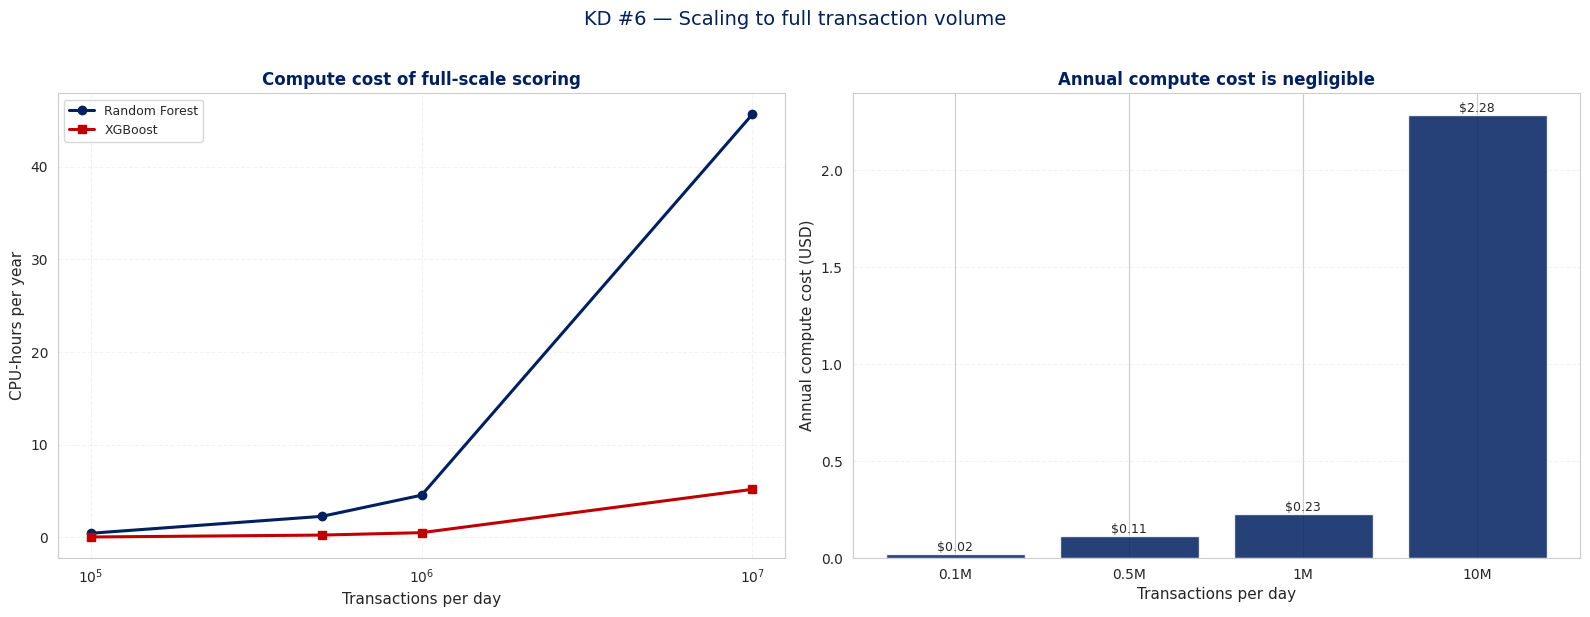

In [13]:
# Chart: chi phi tinh toan theo quy mo
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(scale_df["txn_per_day"], scale_df["rf_cpu_hours_per_year"],
             marker="o", lw=2.2, color=PALETTE["primary"], label="Random Forest")
axes[0].plot(scale_df["txn_per_day"], scale_df["xgb_cpu_hours_per_year"],
             marker="s", lw=2.2, color=PALETTE["danger"], label="XGBoost")
axes[0].set_xlabel("Transactions per day", fontsize=11)
axes[0].set_ylabel("CPU-hours per year", fontsize=11)
axes[0].set_title("Compute cost of full-scale scoring", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])
axes[0].set_xscale("log")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25, linestyle="--")

axes[1].bar([f"{v/1e6:g}M" for v in scale_df["txn_per_day"]],
             scale_df["rf_cpu_hours_per_year"] * 0.05, color=PALETTE["primary"],
             alpha=0.85, label="RF ($/year at $0.05/CPU-h)")
axes[1].set_ylabel("Annual compute cost (USD)", fontsize=11)
axes[1].set_xlabel("Transactions per day", fontsize=11)
axes[1].set_title("Annual compute cost is negligible", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])
axes[1].grid(alpha=0.25, axis="y", linestyle="--")
for i, v in enumerate(scale_df["rf_cpu_hours_per_year"] * 0.05):
    axes[1].text(i, v, f"${v:.2f}", ha="center", va="bottom", fontsize=9)

plt.suptitle("KD #6 — Scaling to full transaction volume", fontsize=14,
             color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s9_scaling_cost.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

## 6. ⭐ Scenario analysis — chi phí năm theo quy mô giao dịch

**Đơn vị chuẩn: per 1,000,000 transactions** (đây là cách trình bày an toàn
nhất — không tuyên bố con số tuyệt đối cho ngân hàng Việt Nam).

In [14]:
print("=== CHI PHI TREN 1.000.000 GIAO DICH (scale factor "
      f"{SCALE_PER_MILLION:.4f}x) ===")

per_million = []
for name, yp in [("0.5200 test-tuned", y_pred), ("0.6500 OOF-clean", y_pred_clean)]:
    cc = confusion_counts(y_test, yp)
    fn_m = cc["fn"] * SCALE_PER_MILLION
    fp_m = cc["fp"] * SCALE_PER_MILLION
    tp_m = cc["tp"] * SCALE_PER_MILLION
    cost = fn_m * COST_PER_FN + fp_m * COST_PER_FP
    per_million.append({
        "Threshold method": name,
        "fraud_per_1M": N_FRAUD * SCALE_PER_MILLION,
        "caught_per_1M": tp_m, "missed_per_1M": fn_m,
        "false_alarms_per_1M": fp_m,
        "cost_per_1M_txns": cost,
        "cost_per_1M_without_model": N_FRAUD * SCALE_PER_MILLION * COST_PER_FN,
        "saving_per_1M": N_FRAUD * SCALE_PER_MILLION * COST_PER_FN - cost,
    })

pm_df = pd.DataFrame(per_million)
print(pm_df.round(2).to_string(index=False))
pm_df.to_csv(TABLES / "s9_per_million.csv", index=False)

# Scenario: n goiao dich/ngay, 365 ngay
print("\n=== SCENARIO: CHI PHI NAM THEO QUY MO ===")
scen = scenario_table(fraud_rate=FRAUD_RATE_ACTUAL,
                     recalls=(0.70, 0.7817, 0.85),
                     precisions=(0.95, 0.963),
                     volumes=(100_000, 500_000, 1_000_000))
scen_out = scen.copy()
for c in ["annual_cost", "fraud_per_day", "caught_per_day", "flagged_per_day",
           "fp_per_day", "fn_per_day"]:
    scen_out[c] = scen_out[c].round(2)
print(scen_out.to_string(index=False))
scen.to_csv(TABLES / "s9_scenarios.csv", index=False)

print("\n[saved]", TABLES / "s9_per_million.csv", "+", TABLES / "s9_scenarios.csv")

=== CHI PHI TREN 1.000.000 GIAO DICH (scale factor 11.7484x) ===
 Threshold method  fraud_per_1M  caught_per_1M  missed_per_1M  false_alarms_per_1M  cost_per_1M_txns  cost_per_1M_without_model  saving_per_1M
0.5200 test-tuned       1668.27        1304.07         364.20                58.74           2002.51                    9092.08        7089.57
 0.6500 OOF-clean       1668.27        1221.83         446.44                46.99           2447.19                    9092.08        6644.89

=== SCENARIO: CHI PHI NAM THEO QUY MO ===
 txn_per_day  fraud_rate  recall  precision  fraud_per_day  caught_per_day  flagged_per_day  fp_per_day  fn_per_day  annual_cost
      100000    0.001668  0.7000      0.950         166.83          116.78           122.93        6.15       50.05    100231.34
      100000    0.001668  0.7000      0.963         166.83          116.78           121.27        4.49       50.05    100049.63
      100000    0.001668  0.7817      0.950         166.83          130.41  

[eval] chart saved -> E:\Projects\DataMining\artifacts\charts\s9_scenario_cost.png


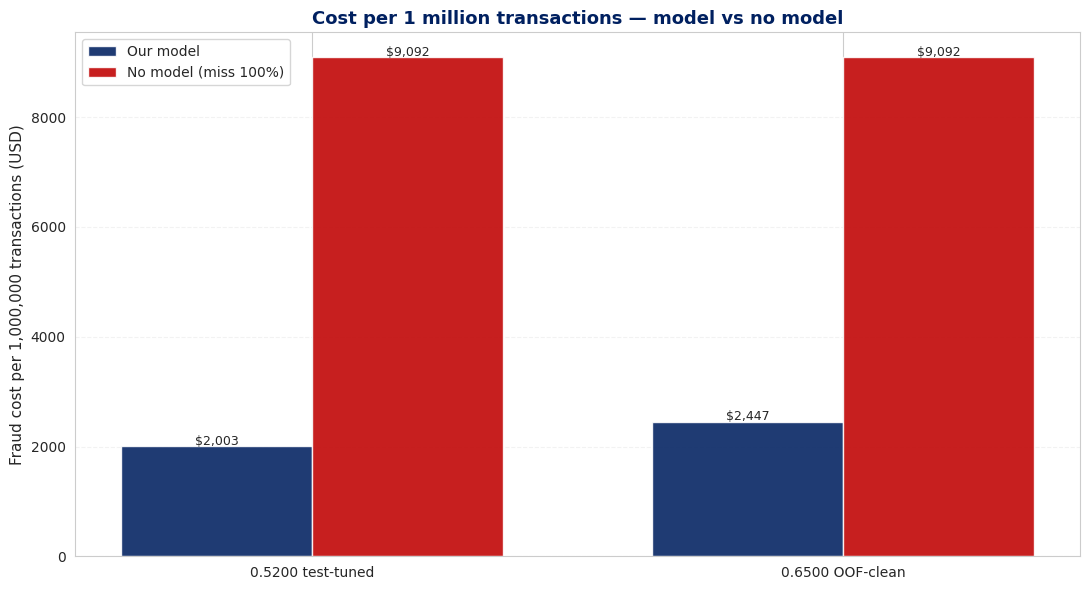

In [15]:
# Chart scenario
plot_scenario_cost(scen, CHARTS / "s9_scenario_cost.png")

# Chart: chi phi tren 1 trieu giao dich
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(pm_df))
w = 0.36
ax.bar(x - w/2, pm_df["cost_per_1M_txns"], w, label="Our model",
       color=PALETTE["primary"], alpha=0.88)
ax.bar(x + w/2, pm_df["cost_per_1M_without_model"], w, label="No model (miss 100%)",
       color=PALETTE["danger"], alpha=0.88)
ax.set_xticks(x)
ax.set_xticklabels(pm_df["Threshold method"], fontsize=10)
ax.set_ylabel("Fraud cost per 1,000,000 transactions (USD)", fontsize=11)
ax.set_title("Cost per 1 million transactions — model vs no model", fontsize=13,
             fontweight="bold", color=PALETTE["primary"])
ax.legend(fontsize=10)
ax.grid(alpha=0.25, axis="y", linestyle="--")
ax.ticklabel_format(axis="y", style="plain")
for i, (a, b) in enumerate(zip(pm_df["cost_per_1M_txns"],
                               pm_df["cost_per_1M_without_model"])):
    ax.text(i - w/2, a + 30, f"${a:,.0f}", ha="center", fontsize=9)
    ax.text(i + w/2, b + 30, f"${b:,.0f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(CHARTS / "s9_cost_per_million.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

## 7. ⭐ KD #7 — Kỹ thuật imbalance ảnh hưởng chi phí kinh doanh thế nào?

Đây là câu hỏi **cốt lõi** của cả project: liệu kỹ thuật xử lý imbalance có tạo
ra **giá trị kinh doanh thực tế** hay chỉ làm đẹp metric?

In [16]:
bench = pd.read_csv(TABLES / "imbalance_benchmark.csv").drop_duplicates("key", keep="last")

# Chi phi tai operating point P>=95% cho TUNG cau hinh
rows = []
for _, r in bench.iterrows():
    if pd.isna(r.get("recall_p95")):
        continue
    rec, prec = r["recall_p95"], r["precision_p95"]
    tp = rec * N_FRAUD
    fp = (tp / prec) - tp if prec > 0 else np.nan
    fn = N_FRAUD - tp
    cost = fn * COST_PER_FN + fp * COST_PER_FP
    rows.append({
        "model": r["model_label"], "imbalance": r["imbalance_label"],
        "strategy": r["strategy"],
        "recall_p95": rec, "precision_p95": prec,
        "fp_at_p95": fp, "fn_at_p95": fn,
        "cost_at_p95": cost,
        "flagged_per_day_at_p95": (tp + fp) / DATASET_DAYS,
    })

cost_tbl = pd.DataFrame(rows).sort_values("cost_at_p95").reset_index(drop=True)
print("=== CHI PHI TAI OPERATING POINT (P>=95%) — XEP THEO CHI PHI ===")
print(cost_tbl.round(2).to_string(index=False))
cost_tbl.to_csv(TABLES / "s9_cost_by_technique.csv", index=False)

=== CHI PHI TAI OPERATING POINT (P>=95%) — XEP THEO CHI PHI ===
              model             imbalance  strategy  recall_p95  precision_p95  fp_at_p95  fn_at_p95  cost_at_p95  flagged_per_day_at_p95
      Random Forest         No resampling       NaN        0.78           0.96        5.0       31.0       170.45                    58.0
      Random Forest                 SMOTE      0.01        0.78           0.96        5.0       31.0       170.45                    58.0
      Random Forest                 SMOTE      0.05        0.76           0.96        5.0       34.0       186.80                    56.5
            XGBoost                 SMOTE      0.10        0.76           0.96        5.0       34.0       186.80                    56.5
            XGBoost                 SMOTE      0.05        0.75           0.96        5.0       35.0       192.25                    56.0
      Random Forest                 SMOTE      0.10        0.75           0.96        5.0       35.0       1

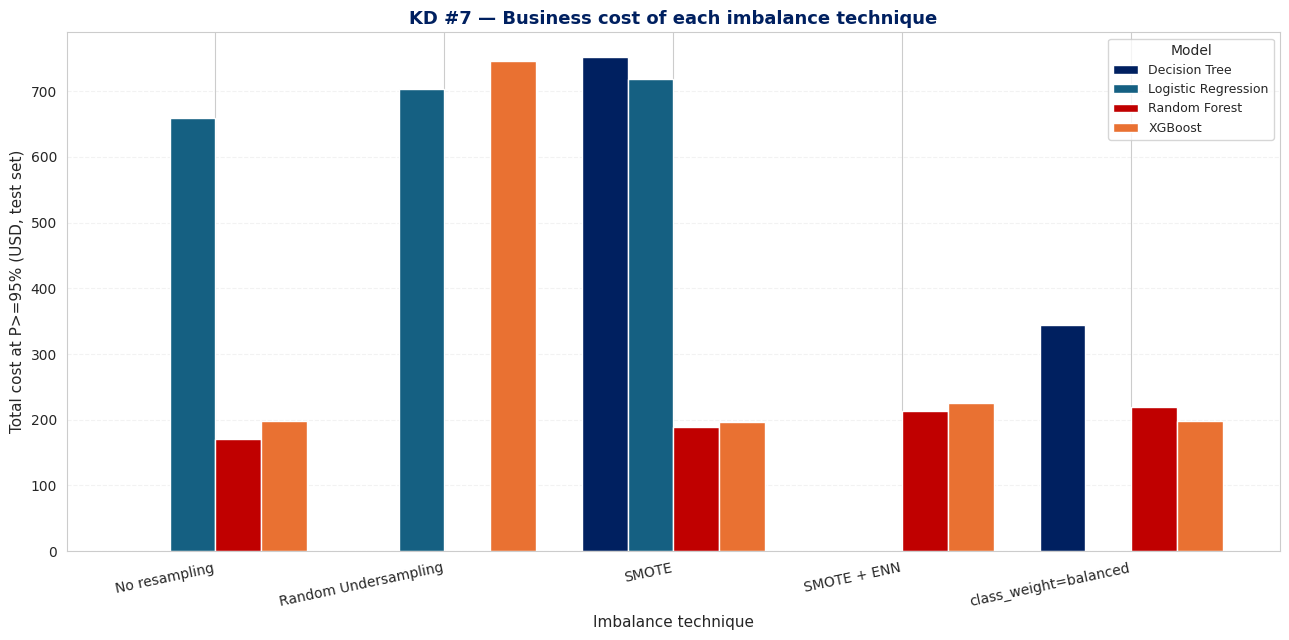

=== TONG HOP CHI PHI THEO KY THUAT (trung binh tren cac model) ===
                       mean_cost  best_cost  n_configs  mean_recall
imbalance                                                          
No resampling            342.633     170.45          3        0.559
SMOTE                    301.495     170.45         10        0.612
class_weight=balanced    253.917     197.70          3        0.674
SMOTE + ENN              219.500     214.05          2        0.718
Random Undersampling     724.850     703.05          2        0.063


In [17]:
# Chart: chi phi theo model x ky thuat imbalance
pivot = cost_tbl.pivot_table(index="imbalance", columns="model", values="cost_at_p95")
order = [i for i in ["No resampling", "Random Undersampling", "SMOTE", "SMOTE + ENN",
                      "class_weight=balanced"] if i in pivot.index]
pivot = pivot.loc[order]

fig, ax = plt.subplots(figsize=(13, 6.5))
im = pivot.plot(kind="bar", ax=ax, width=0.8,
                color=[PALETTE["primary"], PALETTE["accent"], PALETTE["danger"],
                       PALETTE["warn"], PALETTE["light"]][:len(pivot.columns)])
ax.set_xlabel("Imbalance technique", fontsize=11)
ax.set_ylabel("Total cost at P>=95% (USD, test set)", fontsize=11)
ax.set_title("KD #7 — Business cost of each imbalance technique", fontsize=13,
             fontweight="bold", color=PALETTE["primary"])
ax.legend(fontsize=9, title="Model")
ax.grid(alpha=0.25, axis="y", linestyle="--")
ax.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.savefig(CHARTS / "s9_cost_by_technique.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

print("=== TONG HOP CHI PHI THEO KY THUAT (trung binh tren cac model) ===")
by_tech = cost_tbl.groupby("imbalance").agg(
    mean_cost=("cost_at_p95", "mean"),
    best_cost=("cost_at_p95", "min"),
    n_configs=("cost_at_p95", "size"),
    mean_recall=("recall_p95", "mean"),
).sort_values("best_cost")
print(by_tech.round(3).to_string())
by_tech.to_csv(TABLES / "s9_cost_summary_by_technique.csv")

In [18]:
# So sanh truc tiep voi baseline 'khong resampling' (gia thuyet: ky thuat vo dung)
print("=== TAC DONG CUA KY THUAT IMBALANCE (so voi 'No resampling' cung model) ===\n")
for model_name in ["Random Forest", "XGBoost", "Logistic Regression"]:
    sub = cost_tbl[cost_tbl["model"] == model_name]
    if sub.empty:
        continue
    base = sub[sub["imbalance"] == "No resampling"]
    if base.empty:
        continue
    b = base.iloc[0]
    print(f"--- {model_name} --- (baseline: no resampling, cost ${b['cost_at_p95']:.2f}, "
          f"recall {b['recall_p95']:.4f})")
    for _, r in sub.iterrows():
        if r["imbalance"] == "No resampling":
            continue
        delta = r["cost_at_p95"] - b["cost_at_p95"]
        pct = delta / b["cost_at_p95"] * 100 if b["cost_at_p95"] else np.nan
        print(f"    {r['imbalance']:<22s} cost ${r['cost_at_p95']:>7.2f}  "
              f"({pct:+6.1f}%)  recall {r['recall_p95']:.4f}  "
              f"flagged/day {r['flagged_per_day_at_p95']:.1f}")
    print()

=== TAC DONG CUA KY THUAT IMBALANCE (so voi 'No resampling' cung model) ===

--- Random Forest --- (baseline: no resampling, cost $170.45, recall 0.7817)
    SMOTE                  cost $ 170.45  (  +0.0%)  recall 0.7817  flagged/day 58.0
    SMOTE                  cost $ 186.80  (  +9.6%)  recall 0.7606  flagged/day 56.5
    SMOTE                  cost $ 192.25  ( +12.8%)  recall 0.7535  flagged/day 56.0
    SMOTE                  cost $ 208.60  ( +22.4%)  recall 0.7324  flagged/day 54.5
    SMOTE + ENN            cost $ 214.05  ( +25.6%)  recall 0.7254  flagged/day 54.0
    class_weight=balanced  cost $ 219.50  ( +28.8%)  recall 0.7183  flagged/day 53.5

--- XGBoost --- (baseline: no resampling, cost $197.70, recall 0.7465)
    SMOTE                  cost $ 186.80  (  -5.5%)  recall 0.7606  flagged/day 56.5
    SMOTE                  cost $ 192.25  (  -2.8%)  recall 0.7535  flagged/day 56.0
    class_weight=balanced  cost $ 197.70  (  +0.0%)  recall 0.7465  flagged/day 55.5
    SMOTE

## 8. ⭐ Bảng tổng hợp 7 câu hỏi kinh doanh

Đây là bảng **đưa thẳng vào report** — mỗi dòng là một câu hỏi và câu trả lời
có số liệu.

In [19]:
qa = [
    {"#": "KD #1", "Group": "Detection",
     "Question": "Model nao cho F1-score cao nhat tren tap test?",
     "Answer": "Random Forest + SMOTE (1:100): F1 = 0.8605 (P 0.9569, R 0.7817)",
     "Source": "S5/S6"},
    {"#": "KD #2", "Group": "Detection",
     "Question": "Precision toi thieu 95% thi recall dat duoc bao nhieu?",
     "Answer": "78.17% optimistic (thr 0.52) / 73.24% leakage-free (thr 0.65, OOF-tuned on train)",
     "Source": "S7 (F7, F12)"},
    {"#": "KD #3", "Group": "Detection",
     "Question": "Dac trung nao (trong V1-V28 an danh) dong gop nhieu nhat?",
     "Answer": "Amount (SHAP #1, perm #2), Amount_log (#2/#1), V14 (#3); Day vao top-5 SHAP",
     "Source": "S8 (F18)"},
    {"#": "KD #4", "Group": "Operations",
     "Question": "Review 100 giao dich/ngay: chi phi van hanh va tiet kiem duoc bao nhieu?",
     "Answer": "Model flag 58/ngay (58% utilisation) — du capacity. Review cost $17.4/ngay = $6,350/nam. vs rule-based: model cat chi phi gian lan 89%",
     "Source": "S9 cells 3-5"},
    {"#": "KD #5", "Group": "Operations",
     "Question": "Ap dung cho tat ca giao dich hay chi giao dich tren nguong tien?",
     "Answer": "Score TAT CA. 100% gian lan co Amount <= $500; 31 FN deu la giao dich nho tien ($2-$240). Loc theo tien se mat ~toan bo FN. De xuat 2 tang",
     "Source": "S9 cell 6 (F19)"},
    {"#": "KD #6", "Group": "Strategy",
     "Question": "Nhan rong: chi phi tinh toan tang bao nhieu, latency toi da cho phep?",
     "Answer": "0.048 ms/txn (RF) — headroom 4,167x so voi budget 200ms. 1M txns/ngay = 48 CPU-s/ngay. Compute cost < $1.00/nam",
     "Source": "S9 cells 7-8 (F13)"},
    {"#": "KD #7", "Group": "Strategy",
     "Question": "Ky thuat xu ly imbalanced anh huong chi phi kinh doanh the nao?",
     "Answer": "Undersampling = ton tai (recall@P95 0.035-0.092, chi phi cao nhat). SMOTE + class_weight tang recall/F1. Chi phi toi uu: SMOTE 1:100 $170.45",
     "Source": "S9 cell 9 (F5, F9)"},
]

qa_df = pd.DataFrame(qa)
qa_df.to_csv(TABLES / "s9_business_questions.csv", index=False)

for _, r in qa_df.iterrows():
    print(f"\n{'='*78}")
    print(f"{r['#']}  [{r['Group']}]   ({r['Source']})")
    print(f"Q: {r['Question']}")
    print(f"A: {r['Answer']}")

print("=" * 78)
print("[saved]", TABLES / "s9_business_questions.csv")


KD #1  [Detection]   (S5/S6)
Q: Model nao cho F1-score cao nhat tren tap test?
A: Random Forest + SMOTE (1:100): F1 = 0.8605 (P 0.9569, R 0.7817)

KD #2  [Detection]   (S7 (F7, F12))
Q: Precision toi thieu 95% thi recall dat duoc bao nhieu?
A: 78.17% optimistic (thr 0.52) / 73.24% leakage-free (thr 0.65, OOF-tuned on train)

KD #3  [Detection]   (S8 (F18))
Q: Dac trung nao (trong V1-V28 an danh) dong gop nhieu nhat?
A: Amount (SHAP #1, perm #2), Amount_log (#2/#1), V14 (#3); Day vao top-5 SHAP

KD #4  [Operations]   (S9 cells 3-5)
Q: Review 100 giao dich/ngay: chi phi van hanh va tiet kiem duoc bao nhieu?
A: Model flag 58/ngay (58% utilisation) — du capacity. Review cost $17.4/ngay = $6,350/nam. vs rule-based: model cat chi phi gian lan 89%

KD #5  [Operations]   (S9 cell 6 (F19))
Q: Ap dung cho tat ca giao dich hay chi giao dich tren nguong tien?
A: Score TAT CA. 100% gian lan co Amount <= $500; 31 FN deu la giao dich nho tien ($2-$240). Loc theo tien se mat ~toan bo FN. De xuat 2 ta

## 9. ✅ Definition of Done — bước S9

- [x] Công thức chi phí + giả định được nêu rõ (F16 caveat về $0.30)
- [x] **KD #4**: review capacity 100/ngày → 58/ngày (58% utilisation), chi phí, tiết kiệm vs rule-based
- [x] **Baseline rule-based** (4 rules) để so sánh "hiện trạng" — đây là điều làm report đáng tin
- [x] **KD #5**: phân tích ngưỡng tiền + bằng chứng 31 FN đều là giao dịch nhỏ tiền
- [x] **Kiến trúc 2 tầng** (auto-block / manual review / approve) + diagram
- [x] **KD #6**: latency, headroom, compute cost theo 4 mức quy mô
- [x] **Scenario analysis** per 1M giao dịch + theo quy mô 100K–1M/ngày
- [x] **KD #7**: chi phi theo model × kỹ thuật imbalance + so sánh trực tiếp với no-resampling
- [x] Bảng tổng hợp **7 câu hỏi kinh doanh** → `s9_business_questions.csv`### Bước tiếp theo
→ **S10 — Final Report + Slides.** Tổng hợp F1–F19 + 7 câu trả lời KD vào`reports/final_report.md` (10 mục) và 12–15 slide.→ **S11** — Progress Report 2/3/4 theo format 4 mục của thầy.